# Mídias de verificação por entidade e data

Os oito manifestos `hash_tse`, `hash_oab`, `hash_mp` e `hash_confea` (cada qual em duas versões) registram arquivos das entidades em **01/09/2026** e **02/09/2026**. A data é a data indicada no HTML, não uma contagem de votos nem uma atribuição automática de turno eleitoral.

Ambos os conjuntos são lidos de `extracted/`; as figuras geradas ficam embutidas neste notebook mesmo após rodar os testes.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import matplotlib.pyplot as plt

# Funciona tanto no diretório do notebook (test/) quanto na raiz do projeto.
RAIZ = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "extracted").is_dir() and (p / "test" / "manifestos.py").is_file()),
    None,
)
if RAIZ is None:
    raise FileNotFoundError("Abra este notebook na raiz do repositório ou em test/.")
sys.path.insert(0, str(RAIZ / "test"))
from manifestos import load_manifests, is_sha512_base64
from notebook_utils import show_table

manifestos = load_manifests(RAIZ)
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
print(f"Fonte: extracted/ — {len(manifestos)} manifestos HTML")
midias = [m for m in manifestos if m.family == "midias"]
por_entidade_e_data = {}
for m in midias:
    entidade, data = m.subtitle.rsplit(" - ", 1)
    por_entidade_e_data[(entidade, data)] = m
entidades = sorted({e for e, _ in por_entidade_e_data})
print("Entidades:", ", ".join(entidades))

Fonte: extracted/ — 32 manifestos HTML
Entidades: CONFEA, MP, OAB, TSE


## Arquivos exclusivos e compartilhados entre as duas datas
A interseção usa **nomes de arquivo idênticos** dentro de cada entidade. Não supõe que sufixos parecidos designem o mesmo binário.

Entidade,Só 01/09,Nas duas datas,Só 02/09,Mesmo hash nos comuns
CONFEA,10,1,3,1
MP,10,1,3,1
OAB,10,1,3,1
TSE,10,1,3,1


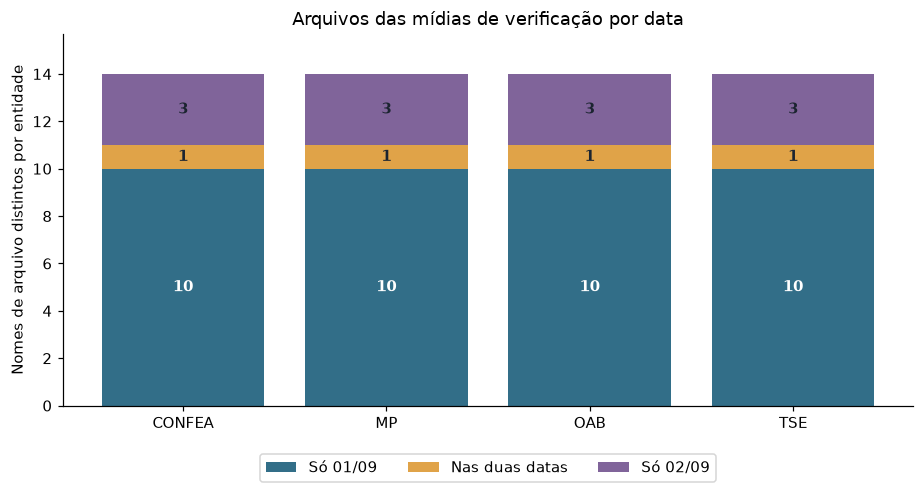

In [2]:
dados = []
for entidade in entidades:
    antigo = {e.path: e.digest for e in por_entidade_e_data[(entidade, "01/09/2026")].entries}
    novo = {e.path: e.digest for e in por_entidade_e_data[(entidade, "02/09/2026")].entries}
    comuns = antigo.keys() & novo.keys()
    dados.append((
        entidade, len(antigo.keys() - novo.keys()), len(comuns),
        len(novo.keys() - antigo.keys()),
        sum(antigo[caminho] == novo[caminho] for caminho in comuns),
    ))

show_table(
    ["Entidade", "Só 01/09", "Nas duas datas", "Só 02/09", "Mesmo hash nos comuns"],
    dados,
)
so_antigos = [x[1] for x in dados]
comuns = [x[2] for x in dados]
so_novos = [x[3] for x in dados]
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.bar(entidades, so_antigos, color="#326e88", label="Só 01/09")
ax.bar(entidades, comuns, bottom=so_antigos, color="#e0a348", label="Nas duas datas")
ax.bar(entidades, so_novos, bottom=[a + b for a, b in zip(so_antigos, comuns)],
       color="#80649a", label="Só 02/09")
for i, (a, b, c) in enumerate(zip(so_antigos, comuns, so_novos)):
    for valor, base in ((a, 0), (b, a), (c, a + b)):
        if valor:
            ax.text(i, base + valor / 2, str(valor), ha="center", va="center",
                    color="white" if valor > 3 else "#1b2430", fontweight="bold")
ax.set_ylabel("Nomes de arquivo distintos por entidade")
ax.set_title("Arquivos das mídias de verificação por data")
ax.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.11))
ax.set_ylim(0, max(a + b + c for a, b, c in zip(so_antigos, comuns, so_novos)) * 1.12)
fig.tight_layout()
plt.show()

## Consultar uma entidade e um arquivo
Altere `ENTIDADE`, `DATA` e `BUSCA`, execute a célula seguinte e veja os hashes completos. A tabela final compara **apenas** os caminhos presentes nas duas datas.

In [3]:
ENTIDADE = "TSE"            # TSE | OAB | MP | CONFEA
DATA = "02/09/2026"        # 01/09/2026 | 02/09/2026
BUSCA = "itnm"              # trecho do nome; vazio exibe todos

In [4]:
manifesto = por_entidade_e_data.get((ENTIDADE.upper(), DATA))
if manifesto is None:
    raise ValueError(f"Manifesto não encontrado: {(ENTIDADE, DATA)!r}")
encontrados = [e for e in manifesto.entries if BUSCA.casefold() in e.path.casefold()]
print(f"Fonte: {manifesto.source} — {len(encontrados)} de {len(manifesto.entries)} arquivos.")
show_table(["Arquivo", "SHA-512 (Base64)"],
           ((e.path, e.digest) for e in encontrados[:20]))
if len(encontrados) > 20:
    print("Exibindo apenas os primeiros 20; refine BUSCA.")

primeira = {e.path: e.digest for e in por_entidade_e_data[(ENTIDADE.upper(), "01/09/2026")].entries}
segunda = {e.path: e.digest for e in por_entidade_e_data[(ENTIDADE.upper(), "02/09/2026")].entries}
show_table(
    ["Arquivo presente nas duas datas", "Hashes publicados iguais?"],
    ((caminho, "Sim" if primeira[caminho] == segunda[caminho] else "Não")
     for caminho in sorted(primeira.keys() & segunda.keys())),
)

Fonte: extracted/hash_tse (1)/HASH_TSE.html — 3 de 4 arquivos.


Arquivo,SHA-512 (Base64)
991itnm.bin,HYysdC2u4lmjmD+J+5jq7kju8aX8wU1BIj13atBRFcZWpHKoj4p1jEGRCAbYopralluwXZF+yE+HqKWZMNOecA==
991itnmJECN.vpe,qOe7tHjsswSQSeKdh84+QRElPrLgwDckrDTbCqgBvKYVZ34j2pW+8nPx6hb90/BdDlboHqG1yjJzeg4gS1QTVw==
991itnmTRAN.vpe,fZZy7K7P0KNoqUlC+EQ+kD1fEBKf7ShQC/JlfCc47brV4u8tQTw/nJc5PaBcY9k8ZSg4b0SqxYFhWf0hGpvUKQ==


Arquivo presente nas duas datas,Hashes publicados iguais?
99.pub,Sim
